In [9]:
import warnings
warnings.filterwarnings('ignore')

from tensorflow.keras.datasets import cifar10

import tensorflow as tf
import numpy
from keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Flatten
from keras.constraints import maxnorm
from tensorflow.keras.optimizers import SGD
from keras.layers.convolutional import Conv2D
from keras.layers.convolutional import MaxPooling2D
from keras.utils import np_utils
from tensorflow.keras import backend as K
from tensorflow.keras.utils import plot_model
import matplotlib.pyplot as plt
from PIL import Image


170498071/170498071 [==============================] - 11s 0us/step


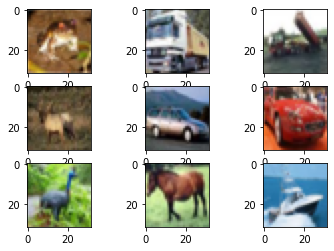

In [10]:
# cargar y observar algunas insancias de CIFAR10 

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# crear un grid de imágenes de 3x3
for i in range(0, 9):
    plt.subplot(330 + 1 + i)
    plt.imshow(Image.fromarray(X_train[i]))
# visualizar
plt.show()

In [11]:
# Modlelo CNN para clasificar el dataset CIFAR-10 
# fijar la semilla del generador random para reproducibilidad
seed = 7
numpy.random.seed(seed)

In [12]:
# cargar el dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

In [13]:
X_train.shape

(50000, 32, 32, 3)

In [14]:
X_test.shape

(10000, 32, 32, 3)

In [15]:
# Voy a utilizar una pequeña fracción para training y testing
X_train_small = X_train [0:10000]
y_train_small = y_train [0:10000]

X_test_small = X_test [0:2500]
y_test_small = y_test [0:2500]

In [16]:
# normalizar las imágenes de 0-255 a 0.0-1.0
X_train_small = X_train_small.astype('float32')
X_test_small = X_test_small.astype('float32')
X_train_small = X_train_small / 255.0
X_test_small = X_test_small / 255.0

In [17]:
# codificar one-hot los labels
y_train_small = np_utils.to_categorical(y_train_small)
y_test_small = np_utils.to_categorical(y_test_small)
num_classes = y_test_small.shape[1]

kernel_constraint=maxnorm(3) es una forma de regularización, para controlar el overfitting, es restringir la matriz de pesos directamente con un término de regularización L2, el cual penaliza los pesos altos en la función de costo. Con esta restricción, se regulariza directamente los pesos
En maxnorm (m), si L2 excede m, escalará toda la matriz de pesos por un factor que reduce la norma a m

In [18]:
# Crear el modelo
model = Sequential()
model.add(Conv2D(32, (3, 3), input_shape=(32, 32, 3), padding='same', activation='relu', kernel_constraint=maxnorm(3)))
model.add(Dropout(0.2))
model.add(Conv2D(32, (3, 3), activation='relu', padding='same', kernel_constraint=maxnorm(3)))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(512, activation='relu', kernel_constraint=maxnorm(3)))
model.add(Dropout(0.5))
model.add(Dense(num_classes, activation='softmax'))

In [19]:
# resumen del modelo
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 32, 32, 32)        896       
                                                                 
 dropout (Dropout)           (None, 32, 32, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 32)        9248      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 16, 16, 32)       0         
 )                                                               
                                                                 
 flatten (Flatten)           (None, 8192)              0         
                                                                 
 dense (Dense)               (None, 512)               4194816   
                                                        

In [20]:
# Compilar el modelo
epochs = 20
lrate = 0.01
decay = lrate/epochs
sgd = SGD(lr=lrate, momentum=0.9, decay=decay, nesterov=False)
model.compile(loss='categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])
#model.summary()

In [21]:
# Entrenar el modelo
history = model.fit(X_train_small, y_train_small, validation_data=(X_test_small, y_test_small), epochs=epochs, batch_size=32)

Epoch 1/20
313/313 [==============================] - 52s 162ms/step - loss: 2.0569 - accuracy: 0.2445 - val_loss: 1.8628 - val_accuracy: 0.3644
Epoch 2/20
313/313 [==============================] - 50s 159ms/step - loss: 1.7947 - accuracy: 0.3542 - val_loss: 1.6622 - val_accuracy: 0.4136
Epoch 3/20
313/313 [==============================] - 53s 168ms/step - loss: 1.6003 - accuracy: 0.4218 - val_loss: 1.4990 - val_accuracy: 0.4632
Epoch 4/20
313/313 [==============================] - 50s 159ms/step - loss: 1.4857 - accuracy: 0.4621 - val_loss: 1.4573 - val_accuracy: 0.4692
Epoch 5/20
313/313 [==============================] - 50s 159ms/step - loss: 1.3737 - accuracy: 0.5033 - val_loss: 1.4279 - val_accuracy: 0.4880
Epoch 6/20
313/313 [==============================] - 50s 161ms/step - loss: 1.2927 - accuracy: 0.5327 - val_loss: 1.3856 - val_accuracy: 0.4988
Epoch 7/20
313/313 [==============================] - 52s 167ms/step - loss: 1.2050 - accuracy: 0.5643 - val_loss: 1.3162 - val_ac

Precisión: 56.84%


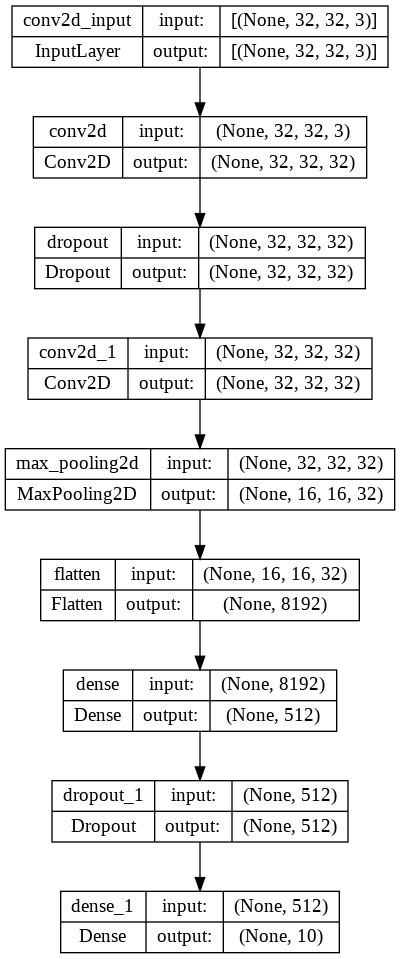

In [22]:
# Evaluación del modelo y guardar imagen de su arquitectura
scores = model.evaluate(X_test_small, y_test_small, verbose=0)
print("Precisión: %.2f%%" % (scores[1]*100))
plot_model(model, show_shapes=True, to_file='cnn_cifar10.png')

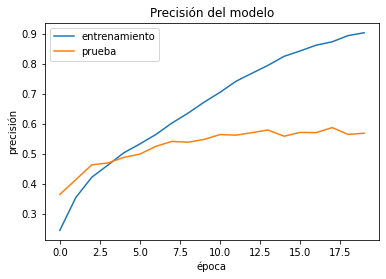

In [23]:
# Resumen histórico de la precisión
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Precisión del modelo')
plt.ylabel('precisión')
plt.xlabel('época')
plt.legend(['entrenamiento','prueba'], loc= 'upper left')
plt.show()

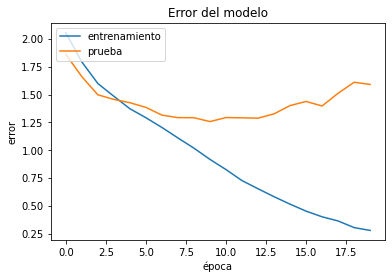

In [24]:
# Resumen histórico del error
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Error del modelo')
plt.ylabel('error')
plt.xlabel('época')
plt.legend(['entrenamiento','prueba'], loc= 'upper left')
plt.show()                                                                                           

In [25]:
from tensorflow.keras.utils import to_categorical
predictions=model.predict(numpy.reshape(X_test[1], (1,32,32,3)))
scores = model.evaluate(X_train_small / 255.0, tf.keras.utils.to_categorical(y_test))

313/313 [==============================] - 10s 32ms/step - loss: 5.7666 - accuracy: 0.1000
